# 12장. CNN 기반 웨이퍼 불량 패턴 분류

「AI로 만드는 제조공정 품질관리 따라하기」 12장 실습 Notebook입니다.
Colab에서는 [런타임] → [런타임 유형 변경]에서 GPU(T4)를 선택하세요. 11장 Notebook으로 만든 캐시가 없으면 다시 만듭니다.

실험 설계(결과를 보기 전에 정함)
- 학습: 공식 Training 중 Lot 번호 앞쪽 80% / 검증: 뒤쪽 20% (조기 종료·모델 선택) / 평가: 공식 Test 118,595장 (마지막에 한 번)
- 입력: 64×64 최근접 보간, 바깥·정상·불량 원-핫 3채널. 학습 때만 90도 회전·좌우 뒤집기 증강
- 주 지표: 9개 유형 macro F1
- 비교: 기본 CNN(가중치 없음 / 클래스 가중치), ResNet18(ImageNet 사전학습 / 무작위 초기화). 시드 42·43·44

In [1]:
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    !git clone -q https://github.com/ady95/manufacturing-ai-tutorial.git
    %cd manufacturing-ai-tutorial/03-defect-inspection/wafermap
    !pip install -q -U kaggle
    from google.colab import userdata
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
Path("results").mkdir(exist_ok=True)

In [2]:
import copy
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from sklearn.metrics import confusion_matrix

from src.wafer_utils import CLASSES, SEED, classification_report_dict, dev_val_split, env_info, prepare

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True              # 입력 크기가 고정이라 cuDNN이 가장 빠른 합성곱 방식을 고르게 한다
ENV = env_info()
print(ENV, "| 장치", DEVICE)

{'python': '3.12.9', 'numpy': '2.5.5', 'pandas': '3.1.1', 'sklearn': '1.9.1', 'opencv': '5.1.0', 'torch': '2.14.1+cu126', 'torchvision': '0.29.1+cu126', 'device': 'NVIDIA GeForce GTX 1080'} | 장치 cuda


## 데이터 준비

In [3]:
D = prepare()
y_all = D["y"]
is_train, is_test = D["split"] == "Training", D["split"] == "Test"
tr, va = dev_val_split(D["lot_num"], is_train)
dup_test = is_test & np.isin(D["md5"], list(set(D["md5"][is_train])))
print("학습", tr.sum(), "| 검증", va.sum(), "| 평가", is_test.sum(), "| Training과 같은 평가 맵", dup_test.sum())

maps_gpu = torch.from_numpy(D["maps"]).to(DEVICE)                 # uint8, 172,950×64×64 ≈ 0.7GB
y_gpu = torch.from_numpy(y_all).to(DEVICE)
idx_tr, idx_va, idx_te = (torch.from_numpy(np.flatnonzero(m)).to(DEVICE) for m in (tr, va, is_test))

counts = np.bincount(y_all[tr], minlength=len(CLASSES))
print(dict(zip(CLASSES, counts)))
w = counts.astype(float) ** -0.5                                   # 드문 유형일수록 큰 가중치(역제곱근)
CLASS_W = torch.tensor(w / w.mean(), dtype=torch.float32, device=DEVICE)
print("클래스 가중치:", dict(zip(CLASSES, CLASS_W.cpu().numpy().round(2))))


def to_input(m):
    """uint8 맵(0·1·2) → 원-핫 3채널 float.

    permute만 하면 메모리 배치가 채널 마지막(channels_last)으로 남아, 이 GPU(GTX 1080)에서는
    학습이 5~9배 느려졌다. contiguous()로 일반 배치로 바꿔 준다.
    """
    return F.one_hot(m.long(), 3).permute(0, 3, 1, 2).float().contiguous()


def augment(x):
    """배치를 8개 묶음으로 나눠 묶음마다 다른 90도 회전·뒤집기를 적용한다."""
    out = torch.empty_like(x)
    perm = torch.randperm(len(x), device=x.device)
    for g, part in enumerate(perm.chunk(8)):
        t = torch.rot90(x[part], g % 4, dims=(2, 3))
        out[part] = torch.flip(t, dims=(3,)) if g >= 4 else t
    return out

학습 43461 | 검증 10894 | 평가 118595 | Training과 같은 평가 맵 3158
{'Center': np.int64(3454), 'Donut': np.int64(408), 'Edge-Loc': np.int64(2376), 'Edge-Ring': np.int64(8545), 'Loc': np.int64(1588), 'Near-full': np.int64(46), 'Random': np.int64(605), 'Scratch': np.int64(493), 'none': np.int64(25946)}
클래스 가중치: {'Center': np.float32(0.42), 'Donut': np.float32(1.23), 'Edge-Loc': np.float32(0.51), 'Edge-Ring': np.float32(0.27), 'Loc': np.float32(0.62), 'Near-full': np.float32(3.66), 'Random': np.float32(1.01), 'Scratch': np.float32(1.12), 'none': np.float32(0.15)}


## 12-1. 기본 CNN

In [4]:
class SmallCNN(nn.Module):
    def __init__(self, n_classes=len(CLASSES)):
        super().__init__()

        def block(c_in, c_out):
            return nn.Sequential(
                nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                nn.Conv2d(c_out, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(),
                nn.MaxPool2d(2))

        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128))   # 64→32→16→8
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3),
                                  nn.Linear(128, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def make_resnet(pretrained: bool):
    weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
    model = torchvision.models.resnet18(weights=weights)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model


n_params = lambda m: sum(p.numel() for p in m.parameters())
print("SmallCNN 파라미터:", n_params(SmallCNN()), "| ResNet18:", n_params(make_resnet(False)))

SmallCNN 파라미터: 289065 | ResNet18: 11181129


In [5]:
@torch.no_grad()
def predict(model, idx, batch=512):
    model.eval()
    logits = [model(to_input(maps_gpu[idx[i:i + batch]])) for i in range(0, len(idx), batch)]
    return torch.cat(logits).softmax(1)


def train_model(make, seed, class_weight=None, lr=1e-3, epochs=30, patience=6, batch=256):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make().to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    loss_fn = nn.CrossEntropyLoss(weight=class_weight)
    best, best_state, wait, hist = -1, None, 0, []
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for ep in range(epochs):
        model.train()
        perm = idx_tr[torch.randperm(len(idx_tr), device=DEVICE)]
        total = 0.0
        for i in range(0, len(perm), batch):
            b = perm[i:i + batch]
            loss = loss_fn(model(augment(to_input(maps_gpu[b]))), y_gpu[b])
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(b)
        pv = predict(model, idx_va).argmax(1).cpu().numpy()
        f1 = classification_report_dict(y_all[va], pv)["macro_f1"]
        hist.append({"epoch": ep + 1, "train_loss": round(total / len(perm), 4), "val_macro_f1": f1})
        if f1 > best:
            best, best_state, wait = f1, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    sec = time.perf_counter() - t0
    model.load_state_dict(best_state)
    return model, hist, sec, best


def evaluate(model):
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    proba = predict(model, idx_te)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    infer = time.perf_counter() - t0
    proba = proba.cpu().numpy()
    pred = proba.argmax(1)
    rep = classification_report_dict(y_all[is_test], pred)
    rep["test_nodup_macro_f1"] = classification_report_dict(y_all[is_test & ~dup_test],
                                                            pred[~dup_test[is_test]])["macro_f1"]
    return proba, rep, infer

In [6]:
CONFIGS = {
    "CNN": dict(make=SmallCNN, class_weight=None),
    "CNN (클래스 가중치)": dict(make=SmallCNN, class_weight=CLASS_W),
}
runs, probas, histories = {}, {}, {}
CACHE = Path("results/12_runs")                    # 실행이 끊겨도 끝난 학습은 다시 하지 않도록 결과를 저장
CACHE.mkdir(exist_ok=True)


def run_config(name, cfg, seeds=(42, 43, 44)):
    runs[name], probas[name] = [], []
    slug = name.replace(" ", "_").replace("(", "").replace(")", "")
    for seed in seeds:
        f_json, f_npy = CACHE / f"{slug}_seed{seed}.json", CACHE / f"{slug}_seed{seed}.npy"
        if f_json.exists() and f_npy.exists():
            saved = json.loads(f_json.read_text(encoding="utf-8"))
            r, hist, proba = saved["run"], saved["hist"], np.load(f_npy)
            sec, best = r["train_sec"], r["val_macro_f1"]
            rep = {"macro_f1": r["test_macro_f1"], "accuracy": r["test_accuracy"]}
            infer = r["infer_sec"]
        else:
            model, hist, sec, best = train_model(cfg["make"], seed, cfg["class_weight"])
            proba, rep, infer = evaluate(model)
            r = {"seed": seed, "epochs": len(hist), "best_epoch": int(np.argmax(
                [h["val_macro_f1"] for h in hist]) + 1), "train_sec": round(sec, 1), "val_macro_f1": best,
                "test_macro_f1": rep["macro_f1"], "test_accuracy": rep["accuracy"],
                "test_nodup_macro_f1": rep["test_nodup_macro_f1"], "infer_sec": round(infer, 2),
                "per_class_f1": {c: v["f1"] for c, v in rep["per_class"].items()}}
            f_json.write_text(json.dumps({"run": r, "hist": hist}, ensure_ascii=False), encoding="utf-8")
            np.save(f_npy, proba.astype(np.float32))
        runs[name].append(r)
        probas[name].append(proba)
        histories[f"{name} seed{seed}"] = hist
        print(f"{name} seed {seed}: epoch {r['epochs']:2d}(최고 {r['best_epoch']}) | 학습 {sec:6.1f}초 | "
              f"검증 {best:.3f} | 평가 macroF1 {rep['macro_f1']:.3f} acc {rep['accuracy']:.3f} | 추론 {infer:.2f}초")


for name, cfg in CONFIGS.items():
    run_config(name, cfg)

CNN seed 42: epoch 13(최고 7) | 학습  204.3초 | 검증 0.803 | 평가 macroF1 0.583 acc 0.958 | 추론 11.42초


CNN seed 43: epoch 20(최고 14) | 학습  305.1초 | 검증 0.785 | 평가 macroF1 0.671 acc 0.958 | 추론 11.03초


CNN seed 44: epoch 15(최고 9) | 학습  236.1초 | 검증 0.847 | 평가 macroF1 0.648 acc 0.960 | 추론 11.20초


CNN (클래스 가중치) seed 42: epoch 23(최고 17) | 학습  358.8초 | 검증 0.853 | 평가 macroF1 0.672 acc 0.958 | 추론 11.25초


CNN (클래스 가중치) seed 43: epoch 15(최고 9) | 학습  239.6초 | 검증 0.747 | 평가 macroF1 0.626 acc 0.956 | 추론 11.34초


CNN (클래스 가중치) seed 44: epoch 13(최고 7) | 학습  209.8초 | 검증 0.675 | 평가 macroF1 0.593 acc 0.947 | 추론 11.80초


## 12-2. ResNet18 전이학습

손실 함수는 기본 CNN 두 가지 중 검증 macro F1 평균이 높은 쪽을 그대로 쓴다(평가 결과를 보지 않고 결정).

In [7]:
val_mean = {k: np.mean([r["val_macro_f1"] for r in v]) for k, v in runs.items()}
use_w = val_mean["CNN (클래스 가중치)"] > val_mean["CNN"]
print("검증 평균:", {k: round(v, 4) for k, v in val_mean.items()}, "→ 클래스 가중치 사용:", use_w)
RES_W = CLASS_W if use_w else None
for name, pre in [("ResNet18 (사전학습)", True), ("ResNet18 (무작위 초기화)", False)]:
    run_config(name, dict(make=lambda pre=pre: make_resnet(pre), class_weight=RES_W))

검증 평균: {'CNN': np.float64(0.8115), 'CNN (클래스 가중치)': np.float64(0.7581)} → 클래스 가중치 사용: False


ResNet18 (사전학습) seed 42: epoch 11(최고 5) | 학습  143.9초 | 검증 0.745 | 평가 macroF1 0.683 acc 0.955 | 추론 9.26초


ResNet18 (사전학습) seed 43: epoch  8(최고 2) | 학습   98.0초 | 검증 0.742 | 평가 macroF1 0.678 acc 0.949 | 추론 8.64초


ResNet18 (사전학습) seed 44: epoch 11(최고 5) | 학습  136.7초 | 검증 0.850 | 평가 macroF1 0.653 acc 0.962 | 추론 8.53초


ResNet18 (무작위 초기화) seed 42: epoch  9(최고 3) | 학습  110.9초 | 검증 0.737 | 평가 macroF1 0.588 acc 0.956 | 추론 8.97초


ResNet18 (무작위 초기화) seed 43: epoch 16(최고 10) | 학습  204.1초 | 검증 0.872 | 평가 macroF1 0.701 acc 0.964 | 추론 8.57초


ResNet18 (무작위 초기화) seed 44: epoch 17(최고 11) | 학습  202.6초 | 검증 0.860 | 평가 macroF1 0.688 acc 0.963 | 추론 8.24초


## 비교표

In [8]:
base = json.loads(Path("results/11_eda_opencv.json").read_text(encoding="utf-8"))["baselines"]
rows = [{"model": "다수 클래스(none)", "val": np.nan, "test": base["다수 클래스(none)"]["macro_f1"], "sd": 0.0,
         "acc": base["다수 클래스(none)"]["accuracy"]},
        {"model": "OpenCV 특징 + RF", "val": base["OpenCV 특징 + RF"]["val_macro_f1"],
         "test": base["OpenCV 특징 + RF"]["macro_f1"], "sd": 0.0, "acc": base["OpenCV 특징 + RF"]["accuracy"],
         "train_sec": base["OpenCV 특징 + RF"]["fit_sec"]}]
for name, rs in runs.items():
    rows.append({"model": name, "val": np.mean([r["val_macro_f1"] for r in rs]),
                 "test": np.mean([r["test_macro_f1"] for r in rs]), "sd": np.std([r["test_macro_f1"] for r in rs]),
                 "acc": np.mean([r["test_accuracy"] for r in rs]),
                 "nodup": np.mean([r["test_nodup_macro_f1"] for r in rs]),
                 "train_sec": np.mean([r["train_sec"] for r in rs]),
                 "infer_ms_per_1k": np.mean([r["infer_sec"] for r in rs]) / is_test.sum() * 1000 * 1000})
table = pd.DataFrame(rows).set_index("model").round(4)
print(table)

                       val    test      sd     acc  train_sec   nodup  \
model                                                                   
다수 클래스(none)           NaN  0.1073  0.0000  0.9334        NaN     NaN   
OpenCV 특징 + RF      0.5743  0.5690  0.0000  0.9327     7.3000     NaN   
CNN                 0.8115  0.6338  0.0372  0.9588   248.5000  0.6321   
CNN (클래스 가중치)       0.7581  0.6300  0.0326  0.9536   269.4000  0.6277   
ResNet18 (사전학습)     0.7788  0.6713  0.0132  0.9555   126.2000  0.6695   
ResNet18 (무작위 초기화)  0.8229  0.6591  0.0504  0.9607   172.5333  0.6577   

                    infer_ms_per_1k  
model                                
다수 클래스(none)                    NaN  
OpenCV 특징 + RF                  NaN  
CNN                         94.5796  
CNN (클래스 가중치)               96.6595  
ResNet18 (사전학습)             74.2864  
ResNet18 (무작위 초기화)          72.4595  


In [9]:
# 검증 macro F1이 가장 높은 설정을 최종 모델로 고른다. 그 설정의 시드 3개 확률을 평균(앙상블)해 오류를 분석한다
chosen = max(runs, key=lambda k: np.mean([r["val_macro_f1"] for r in runs[k]]))
EN = {"CNN": "SmallCNN", "CNN (클래스 가중치)": "SmallCNN (class weight)", "ResNet18 (사전학습)": "ResNet18 (pretrained)",
      "ResNet18 (무작위 초기화)": "ResNet18 (scratch)"}
ens = np.mean(probas[chosen], axis=0)
pred = ens.argmax(1)
rep = classification_report_dict(y_all[is_test], pred)
print("최종 선택:", chosen, "| 시드 3개 앙상블 평가 macroF1", rep["macro_f1"], "accuracy", rep["accuracy"])
print(pd.DataFrame(rep["per_class"]).T)

최종 선택: ResNet18 (무작위 초기화) | 시드 3개 앙상블 평가 macroF1 0.6968 accuracy 0.9657
           precision  recall     f1   support
Center         0.683   0.478  0.563     832.0
Donut          0.837   0.562  0.672     146.0
Edge-Loc       0.724   0.687  0.705    2772.0
Edge-Ring      0.858   0.799  0.828    1126.0
Loc            0.747   0.452  0.563    1973.0
Near-full      0.809   0.979  0.886      95.0
Random         0.874   0.595  0.708     257.0
Scratch        0.838   0.231  0.362     693.0
none           0.977   0.993  0.985  110701.0


## 12-3. 혼동행렬

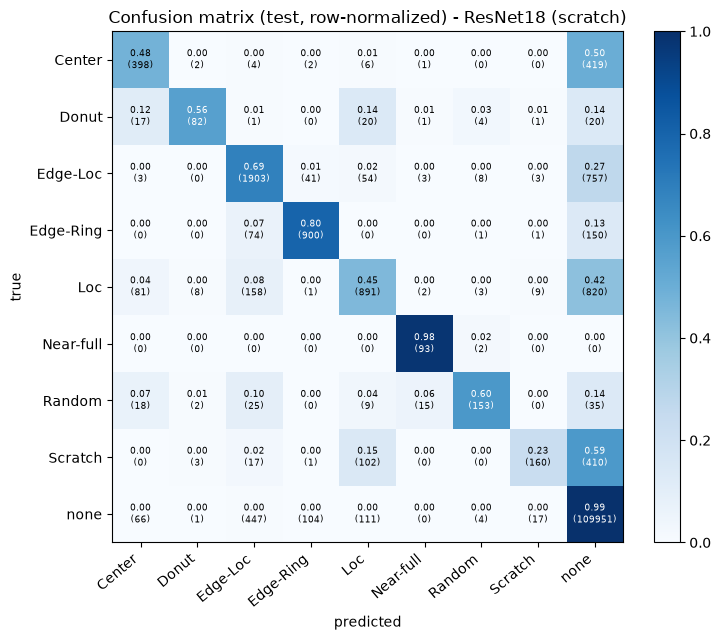

가장 많이 헷갈린 쌍(실제→예측, 건수): [('Loc', 'none', 820), ('Edge-Loc', 'none', 757), ('none', 'Edge-Loc', 447), ('Center', 'none', 419), ('Scratch', 'none', 410), ('Loc', 'Edge-Loc', 158), ('Edge-Ring', 'none', 150), ('none', 'Loc', 111), ('none', 'Edge-Ring', 104), ('Scratch', 'Loc', 102)]


In [10]:
yt = y_all[is_test]
cm = confusion_matrix(yt, pred, labels=range(len(CLASSES)))
cm_norm = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        ax.text(j, i, f"{cm_norm[i, j]:.2f}\n({cm[i, j]})", ha="center", va="center", fontsize=6.5,
                color="white" if cm_norm[i, j] > 0.5 else "black")
ax.set_xticks(range(len(CLASSES)), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(f"Confusion matrix (test, row-normalized) - {EN[chosen]}")
plt.colorbar(im, fraction=0.046); plt.tight_layout()
plt.savefig("results/12_confusion_matrix.png", dpi=110)
plt.show()

pairs = [(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(len(CLASSES)) for j in range(len(CLASSES)) if i != j]
top_pairs = sorted(pairs, key=lambda t: -t[2])[:10]
print("가장 많이 헷갈린 쌍(실제→예측, 건수):", top_pairs)

## 12-4. 오분류 사례

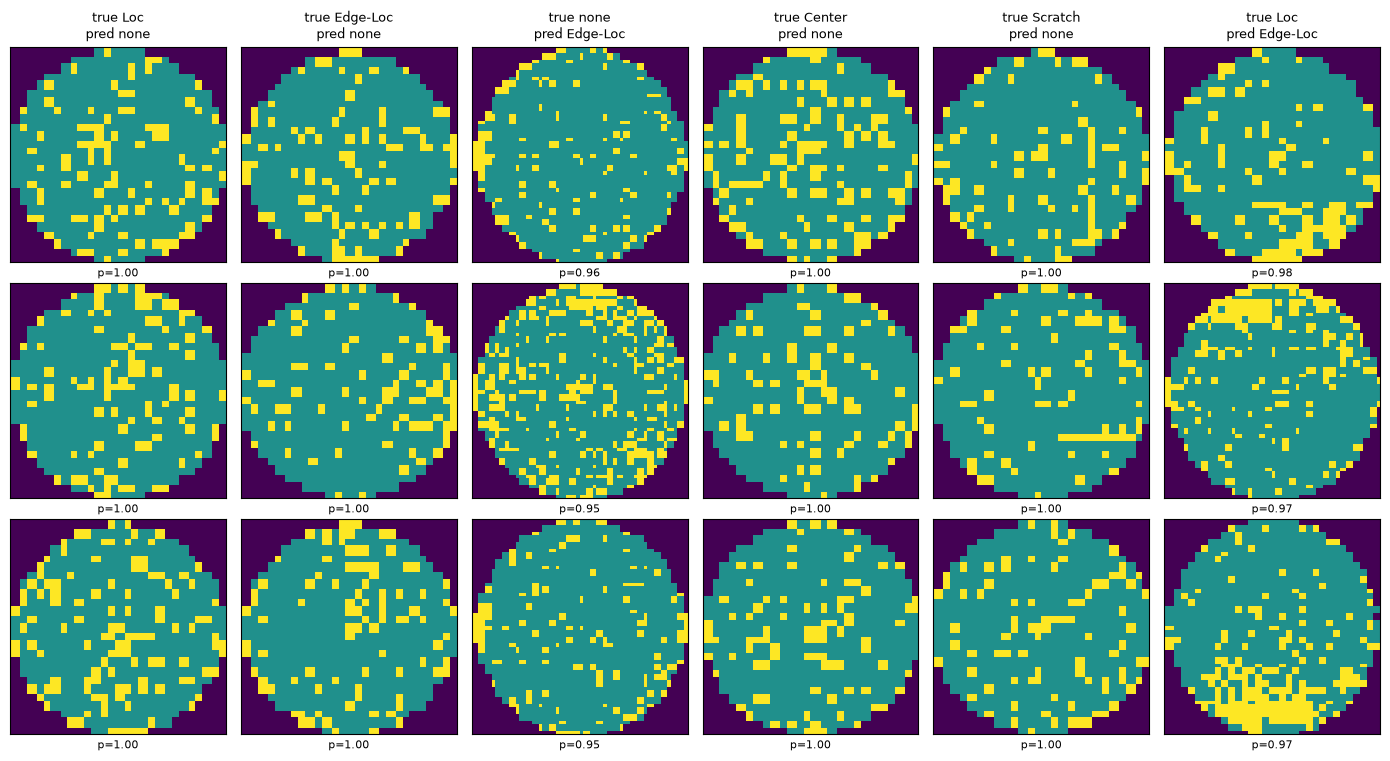

In [11]:
test_idx = np.flatnonzero(is_test)
conf = ens.max(1)
wrong = pred != yt
fig, axes = plt.subplots(3, 6, figsize=(14, 7.6))
shown = 0
for (tname, pname, _) in top_pairs[:6]:
    ti, pi = CLASSES.index(tname), CLASSES.index(pname)
    cand = np.flatnonzero((yt == ti) & (pred == pi))
    cand = cand[np.argsort(-conf[cand])][:3]                       # 확신하며 틀린 순서
    for r, k in enumerate(cand):
        ax = axes[r, shown]
        ax.imshow(D["maps"][test_idx[k]], cmap="viridis", vmin=0, vmax=2, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_xlabel(f"p={conf[k]:.2f}", fontsize=8)
    axes[0, shown].set_title(f"true {tname}\npred {pname}", fontsize=9)
    shown += 1
plt.tight_layout()
plt.savefig("results/12_misclassified.png", dpi=110)
plt.show()

In [12]:
# 라벨이 서로 다른 똑같은 맵(11장)과, 모델이 매우 확신하며 틀린 사례의 비율
md5_te = D["md5"][is_test]
g = pd.DataFrame({"md5": D["md5"], "y": y_all}).groupby("md5")["y"].nunique()
conflict = np.isin(md5_te, g[g > 1].index)
high_wrong = wrong & (conf >= 0.95)
print("평가 오분류:", int(wrong.sum()), "| 그중 확신 0.95 이상:", int(high_wrong.sum()))
print("확신 0.95 이상 오분류의 (실제→예측) 상위:",
      pd.Series([f"{CLASSES[a]}→{CLASSES[b]}" for a, b in zip(yt[high_wrong], pred[high_wrong])]).value_counts()
      .head(6).to_dict())
print("라벨 충돌 맵이 평가에 있는 수:", int(conflict.sum()))

# none으로 예측된 결함(놓친 결함)과 결함으로 예측된 none(과잉 알람)
none_i = CLASSES.index("none")
missed = (yt != none_i) & (pred == none_i)
false_alarm = (yt == none_i) & (pred != none_i)
print(f"놓친 결함: {missed.sum()} / 결함 {int((yt != none_i).sum())} | "
      f"과잉 알람: {false_alarm.sum()} / none {int((yt == none_i).sum())}")

평가 오분류: 4064 | 그중 확신 0.95 이상: 837
확신 0.95 이상 오분류의 (실제→예측) 상위: {'Loc→none': 248, 'Edge-Loc→none': 186, 'Center→none': 163, 'Scratch→none': 143, 'Edge-Ring→none': 30, 'Loc→Center': 17}
라벨 충돌 맵이 평가에 있는 수: 14
놓친 결함: 2611 / 결함 7894 | 과잉 알람: 750 / none 110701


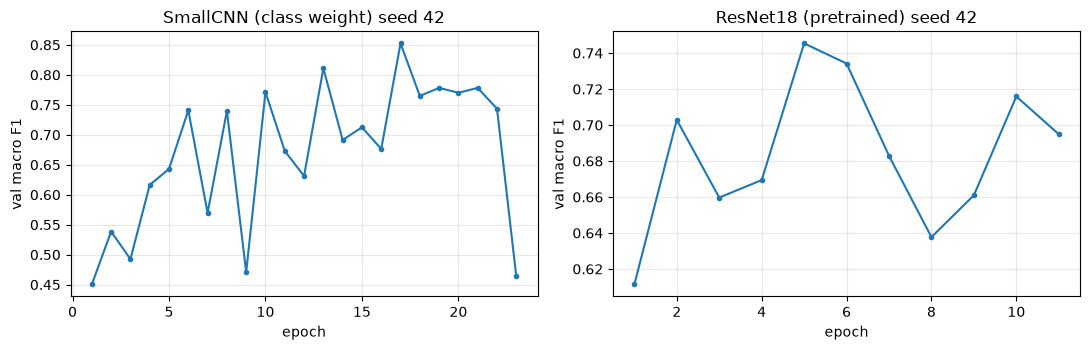

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, name in zip(axes, ["CNN (클래스 가중치)", "ResNet18 (사전학습)"]):
    h = histories[f"{name} seed42"]
    ax.plot([x["epoch"] for x in h], [x["val_macro_f1"] for x in h], marker="o", ms=3)
    ax.set_title({"CNN (클래스 가중치)": "SmallCNN (class weight)", "ResNet18 (사전학습)": "ResNet18 (pretrained)"}[name]
                 + " seed 42"); ax.set_xlabel("epoch"); ax.set_ylabel("val macro F1"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/12_val_curves.png", dpi=110)
plt.show()

In [14]:
out = {
    "env": ENV, "device": DEVICE,
    "split": {"train": int(tr.sum()), "val": int(va.sum()), "test": int(is_test.sum())},
    "class_weight": dict(zip(CLASSES, CLASS_W.cpu().numpy().round(3).tolist())),
    "params": {"SmallCNN": n_params(SmallCNN()), "ResNet18": n_params(make_resnet(False))},
    "resnet_uses_class_weight": bool(use_w),
    "runs": runs,
    "table": table.reset_index().to_dict("records"),
    "chosen": chosen,
    "ensemble": rep,
    "top_confusions": top_pairs,
    "wrong": int(wrong.sum()), "high_conf_wrong": int(high_wrong.sum()),
    "missed_defects": int(missed.sum()), "false_alarms": int(false_alarm.sum()),
    "conflict_in_test": int(conflict.sum()),
    "confusion_matrix": cm.tolist(),
}
Path("results/12_cnn.json").write_text(json.dumps(out, ensure_ascii=False, indent=2, default=float), encoding="utf-8")

11703